# PRAKTIKUM 1

## Pengantar Logika Fuzzy dan Representasi Derajat Keanggotaan

**Nama:** Nurfatimah  
**NIM:** 240306043  
**Kelas:** A  
**Mata Kuliah:** Logika Fuzzy


## A. Studi Kasus

### Sistem Prioritas Tiket Helpdesk TI

Departemen Dukungan TI mengelompokkan waktu tunggu penyelesaian tiket dalam satuan jam ke dalam kategori **"Kritis / Butuh Eskalasi Cepat"**.

Semesta pembicaraan yang digunakan adalah:

0 ≤ x ≤ 24 jam

Pada logika crisp, tiket dianggap kritis apabila waktu tunggu sudah mencapai atau melebihi 8 jam.

Sedangkan pada logika fuzzy, tingkat kekritisan tiket tidak langsung berubah dari tidak kritis menjadi kritis. Tingkat kekritisan berubah secara bertahap berdasarkan waktu tunggu.

Ketentuan fungsi fuzzy yang digunakan:

- Waktu < 4 jam → derajat kritis = 0
- 4 ≤ waktu ≤ 12 jam → derajat kritis naik secara linear
- Waktu > 12 jam → derajat kritis = 1

Studi kasus yang digunakan adalah penentuan prioritas tiket Helpdesk TI berdasarkan waktu tunggu tiket.

Semesta pembicaraan:

U = [0, 24] jam

Kriteria crisp:
- Tiket dianggap kritis jika waktu tunggu ≥ 8 jam.

Pada pendekatan fuzzy, derajat keanggotaan kondisi kritis ditentukan berdasarkan waktu tunggu tiket.

## B. Rancangan Logika Crisp

Pada logika crisp, batas kaku ditetapkan pada 8 jam.

Jika waktu tunggu ≥ 8 jam, maka tiket dikategorikan kritis.

Jika waktu tunggu < 8 jam, maka tiket tidak kritis.

Secara matematis:

χ(x) = 1, jika x ≥ 8

χ(x) = 0, jika x < 8

Keterangan:

- χ(x) = 1 → tiket kritis
- χ(x) = 0 → tiket tidak kritis
- x = waktu tunggu tiket dalam jam

## C. Rancangan Logika Fuzzy

Pada logika fuzzy, tingkat kekritisan tiket ditentukan secara bertahap.

Ketentuannya:

- x < 4 → μ(x) = 0
- 4 ≤ x ≤ 12 → μ(x) naik secara linear
- x > 12 → μ(x) = 1

Untuk mencari persamaan garis linear, digunakan dua titik:

(4, 0) dan (12, 1)

Gradien:

m = (1 - 0) / (12 - 4)

m = 1 / 8

Persamaan garis:

μ(x) = m(x - 4)

Sehingga:

μ(x) = (x - 4) / 8

Maka fungsi keanggotaan fuzzy adalah:

μ(x) = 0,             jika x < 4

μ(x) = (x - 4) / 8,   jika 4 ≤ x ≤ 12

μ(x) = 1,             jika x > 12

Nilai μ(x) berada pada rentang 0 sampai 1.

## 2. Fungsi Keanggotaan Fuzzy

Fungsi keanggotaan yang digunakan adalah fungsi linear naik.

Aturan fungsi keanggotaan:

- μ(x) = 0, jika x < 4
- μ(x) = (x - 4) / (12 - 4), jika 4 ≤ x ≤ 12
- μ(x) = 1, jika x > 12

Keterangan:
- x adalah waktu tunggu tiket dalam jam.
- μ(x) adalah derajat keanggotaan kondisi kritis.

## D. Pengujian Fungsi Crisp dan Fuzzy

Pengujian dilakukan menggunakan data waktu tunggu:

2, 4, 6, 7.9, 8.0, 8.1, 10, 12, 16, dan 24 jam.

Tujuannya adalah membandingkan hasil klasifikasi menggunakan logika crisp dengan derajat keanggotaan menggunakan logika fuzzy.

## E. Visualisasi Perbandingan Crisp dan Fuzzy

Grafik digunakan untuk melihat perbedaan antara logika crisp dan logika fuzzy.

Pada logika crisp, perubahan terjadi secara tiba-tiba pada batas 8 jam.

Pada logika fuzzy, derajat kekritisan meningkat secara bertahap dari waktu 4 jam sampai 12 jam.

Waktu (jam)  | Crisp    | Fuzzy mu(x)  | Interpretasi Fuzzy
-----------------------------------------------------------------
2            | 0.0      | 0.000        | Tingkat kekritisan 0.0% (Tidak Kritis - crisp)
4            | 0.0      | 0.000        | Tingkat kekritisan 0.0% (Tidak Kritis - crisp)
6            | 0.0      | 0.250        | Tingkat kekritisan 25.0% (Tidak Kritis - crisp)
7.9          | 0.0      | 0.488        | Tingkat kekritisan 48.8% (Tidak Kritis - crisp)
8.0          | 1.0      | 0.500        | Tingkat kekritisan 50.0% (KRITIS - crisp)
8.1          | 1.0      | 0.512        | Tingkat kekritisan 51.2% (KRITIS - crisp)
10           | 1.0      | 0.750        | Tingkat kekritisan 75.0% (KRITIS - crisp)
12           | 1.0      | 1.000        | Tingkat kekritisan 100.0% (KRITIS - crisp)
16           | 1.0      | 1.000        | Tingkat kekritisan 100.0% (KRITIS - crisp)
24           | 1.0      | 1.000        | Tingkat kekritisan 100.0% (KRITIS - crisp)

Grafik disimpan se

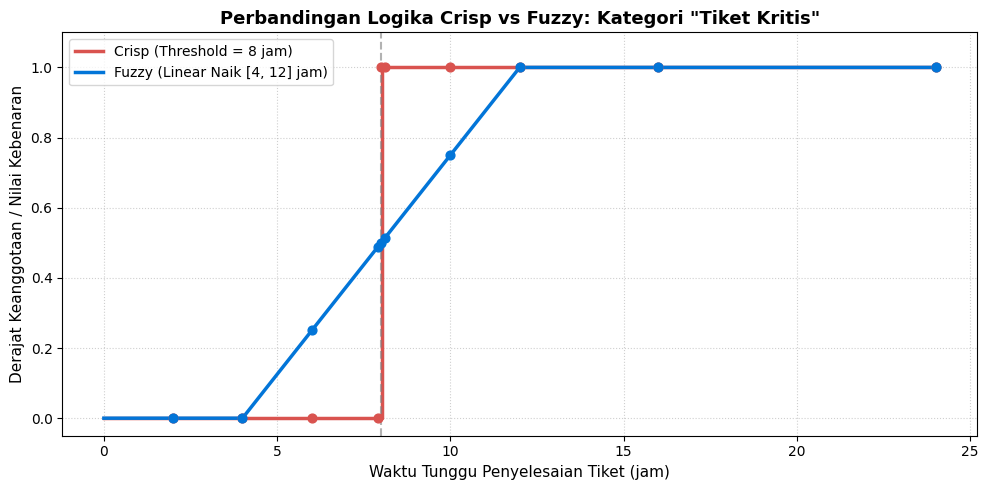

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# 1. RANCANGAN LOGIKA CRISP
# ==========================================================
# Batas kaku: tiket dianggap KRITIS jika waktu tunggu >= 8 jam
#
#             { 1,  x >= 8
# chi(x)  =   {
#             { 0,  x <  8
def crisp_kritis(waktu, threshold=8.0):
    """
    Fungsi karakteristik crisp untuk kategori 'Kritis'.
    Mengembalikan 1 jika waktu tunggu >= threshold, selain itu 0.
    """
    waktu = np.asarray(waktu, dtype=float)
    return np.where(waktu >= threshold, 1.0, 0.0)


# ==========================================================
# 2. RANCANGAN LOGIKA FUZZY
# ==========================================================
# Interval transisi linear naik:
#   x < 4        -> derajat kritis = 0
#   4 <= x <= 12 -> derajat kritis naik linear dari 0 ke 1
#   x > 12       -> derajat kritis = 1
#
# Turunan manual (persamaan garis lurus dari titik (4,0) ke (12,1)):
#   slope m = (1 - 0) / (12 - 4) = 1/8
#   mu(x) = m * (x - 4) = (x - 4) / 8
#
#             { 0,             x < 4
# mu(x)   =   { (x - 4) / 8,   4 <= x <= 12
#             { 1,             x > 12
def fuzzy_kritis(waktu, a=4.0, b=12.0):
    """
    Fungsi keanggotaan fuzzy linear naik untuk kategori 'Kritis'.
    - x <= a       : derajat 0
    - a <= x <= b  : derajat (x - a) / (b - a)
    - x >= b       : derajat 1
    """
    waktu = np.asarray(waktu, dtype=float)
    derajat = (waktu - a) / (b - a)
    return np.clip(derajat, 0.0, 1.0)


# ==========================================================
# 3. PENGUJIAN DENGAN DATA SOAL
# ==========================================================
test_values = [2, 4, 6, 7.9, 8.0, 8.1, 10, 12, 16, 24]

print(f"{'Waktu (jam)':<12} | {'Crisp':<8} | {'Fuzzy mu(x)':<12} | Interpretasi Fuzzy")
print("-" * 65)
for val in test_values:
    c_val = float(crisp_kritis(val))
    f_val = float(fuzzy_kritis(val))
    label_crisp = "KRITIS" if c_val == 1.0 else "Tidak Kritis"
    interpretasi = f"Tingkat kekritisan {f_val * 100:.1f}%"
    print(f"{val:<12} | {c_val:<8.1f} | {f_val:<12.3f} | {interpretasi} ({label_crisp} - crisp)")

# ==========================================================
# 4. GENERASI DATA SEMESTA PEMBICARAAN & VISUALISASI
# ==========================================================
waktu_range = np.linspace(0, 24, 500)
y_crisp = crisp_kritis(waktu_range)
y_fuzzy = fuzzy_kritis(waktu_range)

plt.figure(figsize=(10, 5))

plt.step(waktu_range, y_crisp, label='Crisp (Threshold = 8 jam)',
         color='#d9534f', linewidth=2.5, where='post')

plt.plot(waktu_range, y_fuzzy, label='Fuzzy (Linear Naik [4, 12] jam)',
         color='#0275d8', linewidth=2.5)

for tv in test_values:
    plt.scatter(tv, crisp_kritis(tv), color='#d9534f', zorder=5, s=40)
    plt.scatter(tv, fuzzy_kritis(tv), color='#0275d8', zorder=5, s=40)

plt.axvline(x=8.0, color='gray', linestyle='--', alpha=0.6)

plt.title('Perbandingan Logika Crisp vs Fuzzy: Kategori "Tiket Kritis"',
          fontsize=13, fontweight='bold')
plt.xlabel('Waktu Tunggu Penyelesaian Tiket (jam)', fontsize=11)
plt.ylabel('Derajat Keanggotaan / Nilai Kebenaran', fontsize=11)
plt.ylim(-0.05, 1.1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', fontsize=10)
plt.tight_layout()

plt.savefig('visualisasi_tiket_helpdesk.png', dpi=300)
print("\nGrafik disimpan sebagai 'visualisasi_tiket_helpdesk.png'")

## F. Fungsi Keanggotaan Sigmoid

Selain fungsi keanggotaan linear, digunakan fungsi keanggotaan berbentuk sigmoid.

Persamaan sigmoid:

μ(x) = 1 / (1 + e^(-k(x - x0)))

Dengan:

x0 = 3.5

k = 2.0

Fungsi sigmoid menghasilkan perubahan derajat keanggotaan yang lebih halus dibandingkan batas crisp.

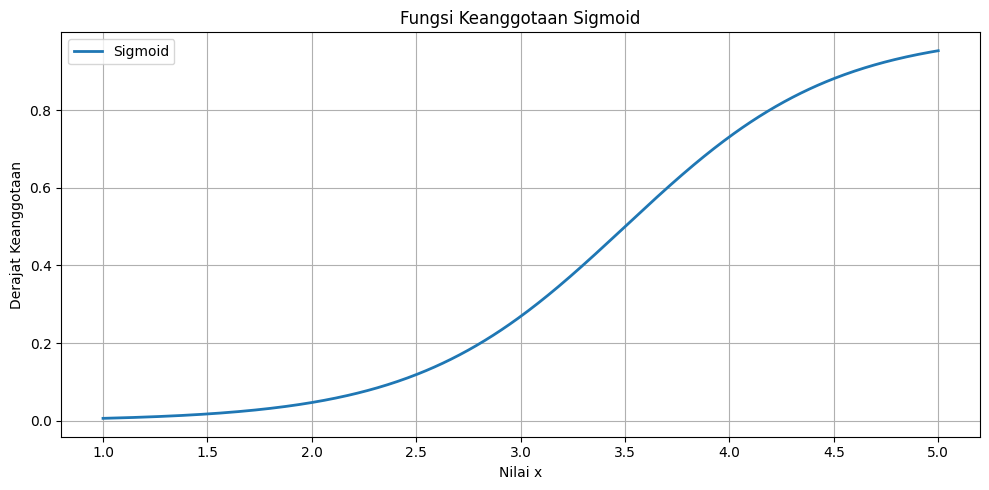

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def sigmoid(x):
    x0 = 3.5
    k = 2.0

    return 1 / (1 + np.exp(-k * (x - x0)))


x = np.linspace(1, 5, 500)

y = sigmoid(x)

plt.figure(figsize=(10, 5))

plt.plot(
    x,
    y,
    label="Sigmoid",
    linewidth=2
)

plt.xlabel("Nilai x")
plt.ylabel("Derajat Keanggotaan")
plt.title("Fungsi Keanggotaan Sigmoid")

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    "fungsi_sigmoid.png",
    dpi=300
)

plt.show()

# G. Analisis

## 1. Mengapa pendekatan logika crisp dinilai kurang adil jika diterapkan pada sistem penilaian kinerja dosen atau penentuan penerima bantuan sosial?

Logika crisp hanya menggunakan dua nilai, yaitu 0 dan 1. Artinya, suatu data hanya dapat dianggap masuk atau tidak masuk ke dalam suatu kategori berdasarkan batas yang telah ditentukan.

Masalah dapat muncul ketika nilai seseorang berada sangat dekat dengan batas tersebut. Sebagai contoh, jika batas penerimaan bantuan ditetapkan pada nilai tertentu, orang yang nilainya sedikit di bawah batas akan mendapatkan hasil yang berbeda dengan orang yang nilainya sedikit di atas batas, walaupun perbedaannya sangat kecil.

Logika fuzzy dapat memberikan derajat keanggotaan secara bertahap sehingga perubahan nilai yang kecil tidak langsung menyebabkan perubahan keputusan secara ekstrem. Dengan demikian, fuzzy dapat digunakan untuk merepresentasikan kondisi yang tidak memiliki batas yang benar-benar tegas.


## 2. Jika suatu nilai suhu memiliki derajat keanggotaan μPanas = 0.7 dan μHangat = 0.4, apakah hal ini melanggar kaidah probabilitas? Jelaskan perbedaannya!

Tidak. Nilai tersebut tidak melanggar kaidah probabilitas karena derajat keanggotaan fuzzy berbeda dengan probabilitas.

Pada fuzzy, satu nilai dapat memiliki derajat keanggotaan pada beberapa himpunan sekaligus. Misalnya suatu suhu dapat memiliki derajat keanggotaan 0.7 pada himpunan Panas dan 0.4 pada himpunan Hangat.

Derajat keanggotaan menunjukkan tingkat kesesuaian suatu nilai terhadap suatu konsep atau himpunan fuzzy. Sementara probabilitas menunjukkan kemungkinan terjadinya suatu kejadian.

Oleh karena itu, derajat keanggotaan fuzzy tidak harus jika dijumlahkan menghasilkan 1.


## 3. Pada kondisi lingkungan nyata yang penuh derau (noisy sensors), mengapa logika fuzzy menghasilkan keputusan yang lebih stabil dibandingkan percabangan if-else konvensional?

Logika fuzzy menggunakan perubahan derajat keanggotaan secara bertahap. Karena tidak langsung memberikan perubahan keputusan yang ekstrem ketika nilai input sedikit berubah, sistem dapat lebih toleran terhadap perubahan kecil atau noise pada data.

Sebaliknya, percabangan if-else biasanya menggunakan batas tertentu. Perubahan kecil di sekitar batas tersebut dapat menyebabkan perubahan hasil secara langsung.

Oleh karena itu, fungsi keanggotaan fuzzy dapat membantu menghasilkan representasi keputusan yang lebih halus pada data yang memiliki variasi.


## 4. Jelaskan apa yang dimaksud dengan semesta pembicaraan (universe of discourse) dan sebutkan contohnya pada sistem monitoring lalu lintas jaringan komputer!

Semesta pembicaraan adalah seluruh rentang nilai yang diperbolehkan atau dipertimbangkan dalam suatu variabel fuzzy.

Contohnya pada sistem monitoring lalu lintas jaringan komputer, variabel yang diamati dapat berupa penggunaan bandwidth. Jika sistem menggunakan rentang 0% sampai 100%, maka semesta pembicaraannya adalah:

0 ≤ bandwidth ≤ 100%

Rentang tersebut kemudian dapat dibagi menjadi beberapa himpunan fuzzy seperti Rendah, Sedang, dan Tinggi.

# H. Kesimpulan

Pada praktikum pertama ini telah dipelajari konsep dasar logika crisp dan logika fuzzy serta perbedaan keduanya.

Logika crisp menggunakan nilai biner 0 dan 1 sehingga suatu data hanya dapat berada pada kondisi benar atau salah. Sementara itu, logika fuzzy menggunakan derajat keanggotaan dalam rentang 0 sampai 1 sehingga suatu nilai dapat memiliki tingkat keanggotaan tertentu terhadap suatu himpunan.

Pada studi kasus sistem prioritas tiket Helpdesk TI, logika crisp menggunakan batas 8 jam. Tiket dengan waktu tunggu kurang dari 8 jam memiliki nilai 0, sedangkan tiket dengan waktu tunggu 8 jam atau lebih memiliki nilai 1.

Pada logika fuzzy, waktu tunggu kurang dari 4 jam memiliki derajat 0, kemudian derajat kekritisan meningkat secara linear dari 4 sampai 12 jam, dan menjadi 1 setelah lebih dari 12 jam.

Hasil pengujian menunjukkan bahwa fuzzy dapat memberikan perubahan nilai secara bertahap, sedangkan crisp menghasilkan perubahan yang langsung pada batas yang telah ditentukan.

Selain fungsi linear, fungsi sigmoid juga dapat digunakan untuk menghasilkan transisi derajat keanggotaan yang lebih halus.

Dengan demikian, logika fuzzy dapat digunakan untuk merepresentasikan kondisi yang tidak memiliki batas yang benar-benar tegas dan menjadi salah satu dasar dalam pengembangan sistem pendukung keputusan.